# LTE: как OFDM превращает многолучевый канал в сотни плоских

Сигнал доходит до приёмника несколькими путями с задержками $\tau_l$: $r(t)=\sum_l h_l\,s(t-\tau_l)+n(t)$. Разброс задержек в городе — единицы микросекунд. Если передавать одну несущую на 5 МГц, символ длится 0.13 мкс, и каждый символ размазывается на десятки соседних — **межсимвольная интерференция (ISI)**, которую CDMA разгребал RAKE-приёмником, а здесь пришлось бы ставить эквалайзер на сотни отводов.

**Идея OFDM**: вместо одного быстрого потока — $N$ медленных на ортогональных поднесущих $k\,\Delta f$. Символ на поднесущей длится $T_u=1/\Delta f=66.7$ мкс $\gg\tau_\text{max}$:
$$x[n]=\frac1{\sqrt N}\sum_{k}X_k\,e^{\,j2\pi kn/N},\qquad n=-N_\text{cp},\dots,N-1$$
Это просто IFFT. Первые $N_\text{cp}$ отсчётов — **циклический префикс**: копия хвоста символа. Пока задержка канала $L\le N_\text{cp}$, линейная свёртка с $h$ на окне FFT совпадает с **циклической**, а циклическая свёртка в базисе Фурье — это умножение:
$$Y_k=H_k\,X_k+W_k,\qquad H_k=\sum_l h_l\,e^{-j2\pi kl/N}$$
Широкополосный канал с памятью превратился в $N$ независимых плоских каналов, и эквалайзер — **одно комплексное деление на поднесущую**. Цена: CP не несёт данных (7 % времени), а часть поднесущих попадает в замирания — это лечит код, растянутый по частоте.

**Нумерология LTE** (36.211): $\Delta f=15$ кГц, слот 0.5 мс = 7 OFDM-символов, субкадр 1 мс, ресурсный блок (RB) = 12 поднесущих × 1 слот = 180 кГц. $f_s=N\Delta f$, так что CP в отсчётах масштабируется с полосой, а во времени — нет:

| Полоса | 1.4 | 3 | 5 | 10 | 20 МГц |
|---|---|---|---|---|---|
| $N_\text{FFT}$ | 128 | 256 | 512 | 1024 | 2048 |
| RB / поднесущих | 6 / 72 | 15 / 180 | 25 / 300 | 50 / 600 | 100 / 1200 |
| $f_s$, МГц | 1.92 | 3.84 | 7.68 | 15.36 | 30.72 |

Нормальный CP: 5.2 мкс у первого символа слота, 4.7 мкс у остальных; расширенный — 16.7 мкс (6 символов в слоте).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc, j0
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.signal import welch

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
BW_MHZ = 5          # 1.4 / 3 / 5 / 10 / 20
PROFILE = "EVA"     # EPA (пешеход) / EVA (машина) / ETU (город): модели 3GPP 36.104
SNR_DB = 20         # SNR на ресурсный элемент для разделов 4–5
FC_GHZ = 2.0        # несущая (доплер)
SPEED_KMH = 120
K_TURBO = 1024      # длина блока турбокода (есть QPP для 40, 512, 1024, 2048, 6144)
TURBO_ITERS = 8
CELL_ID = 0

rng = np.random.default_rng(SEED)

## Примитивы: OFDM, каналы 3GPP, QAM, CRS, турбокод

In [2]:
# ---------- нумерология ----------
DF = 15e3
NUM = {1.4: (128, 6), 3: (256, 15), 5: (512, 25), 10: (1024, 50), 20: (2048, 100)}
N_FFT, N_RB = NUM[BW_MHZ]
FS = N_FFT * DF
N_SC = 12 * N_RB
T_U = 1 / DF
CP = np.array([160] + [144] * 6) * N_FFT // 2048            # нормальный CP, 7 символов в слоте
CP_EXT = 512 * N_FFT // 2048                                 # расширенный CP
SC_IDX = np.r_[-N_SC // 2:0, 1:N_SC // 2 + 1]                # занятые поднесущие, DC пустая

def sym_starts(nsym, cp=CP):
    """Индекс начала полезной части (после CP) каждого символа."""
    cps = np.array([cp[s % len(cp)] for s in range(nsym)])
    return np.cumsum(np.r_[0, cps[:-1] + N_FFT]) + cps

def ofdm_mod(X, cp=None):
    """X (..., Nsym, N_SC) → отсчёты (..., L). cp — длины CP (циклически по символам). Мощность на поднесущую 1."""
    cp = CP if cp is None else np.atleast_1d(cp)
    G = np.zeros(X.shape[:-1] + (N_FFT,), complex)
    G[..., SC_IDX % N_FFT] = X
    x = np.fft.ifft(G, axis=-1) * np.sqrt(N_FFT)
    return np.concatenate([np.concatenate([x[..., s, N_FFT - cp[s % len(cp)]:], x[..., s, :]], -1)
                           for s in range(X.shape[-2])], -1)

def ofdm_demod(y, nsym, cp=None):
    cp = CP if cp is None else np.atleast_1d(cp)
    st = sym_starts(nsym, cp)
    seg = np.stack([y[..., p:p + N_FFT] for p in st], -2)
    return np.fft.fft(seg, axis=-1)[..., SC_IDX % N_FFT] / np.sqrt(N_FFT)

# ---------- каналы 3GPP 36.104 (задержки нс, мощности дБ) ----------
PROFILES = {
    "EPA": ([0, 30, 70, 90, 110, 190, 410], [0, -1, -2, -3, -8, -17.2, -20.8]),
    "EVA": ([0, 30, 150, 310, 370, 710, 1090, 1730, 2510], [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7, -12, -16.9]),
    "ETU": ([0, 50, 120, 200, 230, 500, 1600, 2300, 5000], [-1, -1, -1, 0, 0, 0, -3, -5, -7]),
}

def pdp(name):
    t, p = PROFILES[name]
    p = 10 ** (np.array(p) / 10)
    return np.array(t) * 1e-9, p / p.sum()

def tau_rms(name):
    t, p = pdp(name)
    return np.sqrt((p * t**2).sum() - (p * t).sum()**2)

def tap_delays(name):
    """Задержки лучей, округлённые до отсчёта."""
    return np.round(pdp(name)[0] * FS).astype(int)

def fading(name, n_samp, fd, rng, batch=(), n_sin=16):
    """Релеевский многолучевой канал: коэффициенты лучей g (*batch, n_samp, P), задержки — tap_delays(name).
    Каждый луч — модель Джейкса (n_sin волн с равномерными углами прихода), fd — макс. доплер, Гц; fd = 0 — статика."""
    p = pdp(name)[1]
    tt = np.arange(n_samp) / FS
    g = np.empty(batch + (n_samp, len(p)), complex)
    for k in range(len(p)):
        if fd == 0:
            gk = (rng.standard_normal(batch + (1,)) + 1j * rng.standard_normal(batch + (1,))) / np.sqrt(2)
        else:
            al = 2 * np.pi * (np.arange(n_sin) + rng.random(batch + (n_sin,))) / n_sin
            ph = rng.uniform(0, 2 * np.pi, batch + (n_sin,))
            gk = np.exp(1j * (2 * np.pi * fd * np.cos(al)[..., None] * tt + ph[..., None])).sum(-2) / np.sqrt(n_sin)
        g[..., k] = np.sqrt(p[k]) * gk
    return g

def apply_channel(x, g, d):
    """y[n] = Σ_k g[n,k]·x[n − d_k]; g (..., n, P) или (..., 1, P) для статического канала."""
    y = np.zeros(x.shape, complex); n = x.shape[-1]
    for k, dk in enumerate(d):
        gk = np.broadcast_to(g[..., k], x.shape)
        y[..., dk:] += gk[..., dk:] * x[..., :n - dk]
    return y

def freq_response(g, d):
    """H_k = Σ_l g_l·exp(−j2πk d_l/N) на занятых поднесущих: g (..., P) → (..., N_SC)"""
    return g @ np.exp(-2j * np.pi * np.outer(d, SC_IDX) / N_FFT)

def awgn(shape, n0, rng):
    return np.sqrt(n0 / 2) * (rng.standard_normal(shape) + 1j * rng.standard_normal(shape))

# ---------- QAM с отображением Грея из 36.211 ----------
class QAM:
    """Q = 2/4/6 бит. Биты чередуются I,Q: b0,b1 — знаки; b2,b3 и b4,b5 — амплитуды по Грею. Средняя мощность 1."""
    LV = {1: {(): 1}, 2: {(0,): 1, (1,): 3}, 3: {(0, 0): 3, (0, 1): 1, (1, 0): 5, (1, 1): 7}}
    def __init__(self, Q):
        self.Q, self.m = Q, Q // 2
        self.ax_bits = ((np.arange(2**self.m)[:, None] >> np.arange(self.m)[::-1]) & 1)
        self.amp = np.array([(1 - 2 * b[0]) * self.LV[self.m][tuple(b[1:])] for b in self.ax_bits], float)
        self.amp /= np.sqrt(2 * (self.amp**2).mean())
        nI = len(self.amp)
        self.const = (self.amp[:, None] + 1j * self.amp[None, :]).ravel()
        B = np.empty((nI * nI, Q), int)
        B[:, 0::2] = np.repeat(self.ax_bits, nI, 0); B[:, 1::2] = np.tile(self.ax_bits, (nI, 1))
        self.cbits, self.w = B, 2 ** np.arange(Q)[::-1]
        self.idx_of = np.zeros(2**Q, int); self.idx_of[B @ self.w] = np.arange(nI * nI)
    def mod(self, b):
        return self.const[self.idx_of[b.reshape(b.shape[:-1] + (-1, self.Q)) @ self.w]]
    def llr(self, z, n0):
        """max-log LLR = ln P(0)/P(1) для эквализованных z с эффективным шумом n0 (поэлементно)."""
        L = np.empty(z.shape + (self.Q,))
        for ax, comp in ((0, z.real), (1, z.imag)):
            d = (comp[..., None] - self.amp) ** 2 / (np.broadcast_to(n0, z.shape)[..., None] / 2)
            for j in range(self.m):
                b = self.ax_bits[:, j]
                L[..., 2 * j + ax] = 0.5 * (d[..., b == 1].min(-1) - d[..., b == 0].min(-1))
        return L.reshape(z.shape[:-1] + (-1,))
    def hard(self, z):
        return self.cbits[np.abs(z[..., None] - self.const).argmin(-1)].reshape(z.shape[:-1] + (-1,))

def _qam_ab(Q):
    """BER ≈ a·erfc(√(b·Es/N0)): точно для QPSK, ближайшие соседи (Грей) для 16/64QAM."""
    M = 2**Q
    return (0.5, 0.5) if Q == 2 else ((2 / Q) * (1 - 1 / np.sqrt(M)), 3 / (2 * (M - 1)))

def ber_awgn(Q, esn0):
    a, b = _qam_ab(Q)
    return a * erfc(np.sqrt(b * np.asarray(esn0)))

def ber_rayleigh(Q, esn0_mean):
    """То же, усреднённое по экспоненциальному SNR: E[erfc(√(bγ))] = 1 − √(bγ̄/(1+bγ̄))."""
    a, b = _qam_ab(Q); bg = b * np.asarray(esn0_mean)
    return a * (1 - np.sqrt(bg / (1 + bg)))

# ---------- CRS: Gold-последовательность длины 31 (36.211 §7.2, §6.10.1) ----------
def gold_c(c_init, n, Nc=1600):
    x1 = np.zeros(Nc + n + 31, np.uint8); x2 = np.zeros_like(x1)
    x1[0] = 1; x2[:31] = (c_init >> np.arange(31)) & 1
    for i in range(Nc + n):
        x1[i + 31] = x1[i + 3] ^ x1[i]
        x2[i + 31] = x2[i + 3] ^ x2[i + 2] ^ x2[i + 1] ^ x2[i]
    return x1[Nc:Nc + n] ^ x2[Nc:Nc + n]

def crs_grid(n_sym=14, cell_id=CELL_ID, n_rb_max=110):
    """Маска и значения CRS порта 0: символы l=0 и l=4 слота, каждая 6-я поднесущая, сдвиг 3 и v_shift = cell_id mod 6."""
    M = np.zeros((n_sym, N_SC), bool); V = np.zeros((n_sym, N_SC), complex)
    vs = cell_id % 6
    for s in range(n_sym):
        ns, l = (s // 7) % 20, s % 7
        if l not in (0, 4):
            continue
        c = gold_c(2**10 * (7 * (ns + 1) + l + 1) * (2 * cell_id + 1) + 2 * cell_id + 1, 4 * n_rb_max)
        r = ((1 - 2.0 * c[0::2]) + 1j * (1 - 2.0 * c[1::2])) / np.sqrt(2)
        m = np.arange(2 * N_RB)
        k = 6 * m + ((0 if l == 0 else 3) + vs) % 6
        M[s, k] = True; V[s, k] = r[m + n_rb_max - N_RB]
    return M, V

def chan_est(Y, Xp, mask, time_mode="linear"):
    """LS на пилотах → линейная интерполяция по частоте → по времени ('linear' между пилотными символами или 'hold')."""
    psyms = np.nonzero(mask.any(1))[0]; k = np.arange(N_SC)
    Hp = []
    for s in psyms:
        kk = np.nonzero(mask[s])[0]
        ls = Y[..., s, kk] / Xp[s, kk]
        f = lambda v: np.interp(k, kk, v)
        Hp.append(np.apply_along_axis(f, -1, ls.real) + 1j * np.apply_along_axis(f, -1, ls.imag))
    Hp = np.stack(Hp, -2)
    nsym = Y.shape[-2]
    if time_mode == "hold":
        return Hp[..., np.maximum(np.searchsorted(psyms, np.arange(nsym), "right") - 1, 0), :]
    j = np.clip(np.searchsorted(psyms, np.arange(nsym)), 1, len(psyms) - 1)
    w = ((np.arange(nsym) - psyms[j - 1]) / (psyms[j] - psyms[j - 1]))[:, None]
    w = np.minimum(w, 1.0)                                   # за последним пилотом — удержание
    return (1 - w) * Hp[..., j - 1, :] + w * Hp[..., j, :]

# ---------- турбокод LTE (36.212 §5.1.3) ----------
QPP = {40: (3, 10), 512: (31, 64), 1024: (31, 64), 2048: (31, 64), 6144: (263, 480)}

def qpp(K):
    """Квадратичный перестановочный перемежитель Π(i) = (f1·i + f2·i²) mod K."""
    f1, f2 = QPP[K]
    i = np.arange(K, dtype=np.int64)
    return (f1 * i + f2 * i * i) % K

# RSC: G(D) = [1, g1/g0], g0 = 1+D²+D³ (13₈) — обратная связь, g1 = 1+D+D³ (15₈); 8 состояний
NXT = np.zeros((8, 2), int); PAR = np.zeros((8, 2), int); FB = np.zeros(8, int)
for s in range(8):
    s1, s2, s3 = (s >> 2) & 1, (s >> 1) & 1, s & 1
    FB[s] = s2 ^ s3                                           # вход, гасящий обратную связь → хвост
    for u in (0, 1):
        a = u ^ s2 ^ s3
        NXT[s, u] = (a << 2) | (s1 << 1) | s2
        PAR[s, u] = a ^ s1 ^ s3
PREV_S = np.zeros((8, 2), int); PREV_U = np.zeros((8, 2), int)
_c = np.zeros(8, int)
for s in range(8):
    for u in (0, 1):
        ns = NXT[s, u]; PREV_S[ns, _c[ns]] = s; PREV_U[ns, _c[ns]] = u; _c[ns] += 1

def rsc_encode(u):
    B, K = u.shape
    s = np.zeros(B, int); z = np.empty((B, K), int)
    for k in range(K):
        z[:, k] = PAR[s, u[:, k]]; s = NXT[s, u[:, k]]
    xt = np.empty((B, 3), int); zt = np.empty((B, 3), int)
    for k in range(3):                                        # терминирование в нулевое состояние
        ut = FB[s]; xt[:, k] = ut; zt[:, k] = PAR[s, ut]; s = NXT[s, ut]
    return z, xt, zt

def turbo_encode(u):
    """u (B,K) → (B, 3K+12): тройки [систематика, проверка 1, проверка 2] и 12 хвостовых бит. R ≈ 1/3."""
    z1, xt1, zt1 = rsc_encode(u)
    z2, xt2, zt2 = rsc_encode(u[:, qpp(u.shape[1])])
    return np.concatenate([np.stack([u, z1, z2], -1).reshape(len(u), -1), xt1, zt1, xt2, zt2], 1)

def _maxstar(a, b, exact):
    m = np.maximum(a, b)
    return m + np.log1p(np.exp(-np.abs(a - b))) if exact else m

def bcjr(Ls, Lp, La, Lst, Lpt, exact):
    """MAP-декодер RSC (log-MAP или max-log-MAP) по решётке с хвостом. Вход/выход — LLR ln P(0)/P(1), (B,K)."""
    B, K = Ls.shape
    Lx = np.concatenate([Ls + La, Lst], 1).T; Lz = np.concatenate([Lp, Lpt], 1).T
    zs = 1 - 2 * PAR; xs = np.array([1, -1])
    g = 0.5 * (Lx[:, :, None, None] * xs + Lz[:, :, None, None] * zs)     # γ_t(s,u): (T,B,8,2)
    T = K + 3
    al = np.full((T + 1, B, 8), -1e9); al[0, :, 0] = 0
    for t in range(T):
        a = _maxstar(al[t][:, PREV_S[:, 0]] + g[t][:, PREV_S[:, 0], PREV_U[:, 0]],
                     al[t][:, PREV_S[:, 1]] + g[t][:, PREV_S[:, 1], PREV_U[:, 1]], exact)
        al[t + 1] = a - a.max(1, keepdims=True)
    be = np.full((B, 8), -1e9); be[:, 0] = 0
    Lout = np.empty((B, K))
    for t in range(T - 1, -1, -1):
        m = al[t][:, :, None] + g[t] + be[:, NXT]
        if t < K:
            red = (lambda v: np.logaddexp.reduce(v, 1)) if exact else (lambda v: v.max(1))
            Lout[:, t] = red(m[:, :, 0]) - red(m[:, :, 1])
        b = _maxstar(be[:, NXT[:, 0]] + g[t][:, :, 0], be[:, NXT[:, 1]] + g[t][:, :, 1], exact)
        be = b - b.max(1, keepdims=True)
    return Lout

def turbo_decode(L, K, iters=TURBO_ITERS, exact=True, scale=0.7, cb=None):
    """Итеративный декодер: два BCJR обмениваются внешней информацией через QPP.
    Для max-log внешние LLR домножаются на scale (компенсация переоценки, как α в min-sum)."""
    m = L[:, :3 * K].reshape(-1, K, 3); t = L[:, 3 * K:]
    Ls, Lp1, Lp2 = m[..., 0], m[..., 1], m[..., 2]
    pi = qpp(K); ipi = np.argsort(pi)
    sc = 1.0 if exact else scale
    La = np.zeros_like(Ls)
    for it in range(iters):
        L1 = bcjr(Ls, Lp1, La, t[:, 0:3], t[:, 3:6], exact)
        Le1 = sc * (L1 - Ls - La)
        L2 = bcjr(Ls[:, pi], Lp2, Le1[:, pi], t[:, 6:9], t[:, 9:12], exact)
        La = (sc * (L2 - Ls[:, pi] - Le1[:, pi]))[:, ipi]
        if cb: cb(it, L2[:, ipi])
    return (L2[:, ipi] < 0).astype(int)

def puncture_half(K):
    """Маска R≈1/2: проверки двух кодеров выкалываются через одну (стандартный rate matching LTE делает это через кольцевой буфер)."""
    m = np.ones((K, 3), bool); m[1::2, 1] = False; m[0::2, 2] = False
    return np.r_[m.ravel(), np.ones(12, bool)]

# самопроверки
assert all(len(np.unique(qpp(K))) == K for K in QPP), "QPP не перестановка"
_u = rng.integers(0, 2, (4, 40)); _c = turbo_encode(_u)
assert np.all(turbo_decode(4.0 * (1 - 2 * _c), 40) == _u)
for Q in (2, 4, 6):
    _b = rng.integers(0, 2, (3, 60 * Q)); assert np.all(QAM(Q).hard(QAM(Q).mod(_b)) == _b)
_X = QAM(2).mod(rng.integers(0, 2, (14, 2 * N_SC)))
print(f"BW {BW_MHZ} МГц: N_FFT = {N_FFT}, {N_RB} RB = {N_SC} поднесущих, f_s = {FS/1e6:.2f} МГц, "
      f"отсчёт {1e9/FS:.0f} нс")
print(f"CP: {CP[0]}/{CP[1]} отсчётов = {CP[0]/FS*1e6:.2f}/{CP[1]/FS*1e6:.2f} мкс, расширенный {CP_EXT} = {CP_EXT/FS*1e6:.1f} мкс; "
      f"субкадр = {len(ofdm_mod(_X))} отсчётов = {len(ofdm_mod(_X))/FS*1e3:.3f} мс")
print("OFDM без канала: max|Y − X| =", f"{np.abs(ofdm_demod(ofdm_mod(_X), 14) - _X).max():.1e}")

BW 5 МГц: N_FFT = 512, 25 RB = 300 поднесущих, f_s = 7.68 МГц, отсчёт 130 нс
CP: 40/36 отсчётов = 5.21/4.69 мкс, расширенный 128 = 16.7 мкс; субкадр = 7680 отсчётов = 1.000 мс
OFDM без канала: max|Y − X| = 7.4e-16


## 1. Многолучевой канал: во времени и по частоте
Слева — профили задержек 3GPP. Пунктир — нормальный CP: EPA и EVA укладываются с большим запасом, у ETU последний луч (5 мкс) немного вылезает. Справа — $|H(f)|$ одной реализации на всей полосе: чем больше разброс задержек $\tau_\text{rms}$, тем чаще замирания по частоте. Полоса когерентности $B_c\approx1/(5\tau_\text{rms})$ — на каком масштабе канал «примерно плоский». Поднесущая 15 кГц много уже $B_c$ для всех профилей: на ней канал — одно комплексное число.

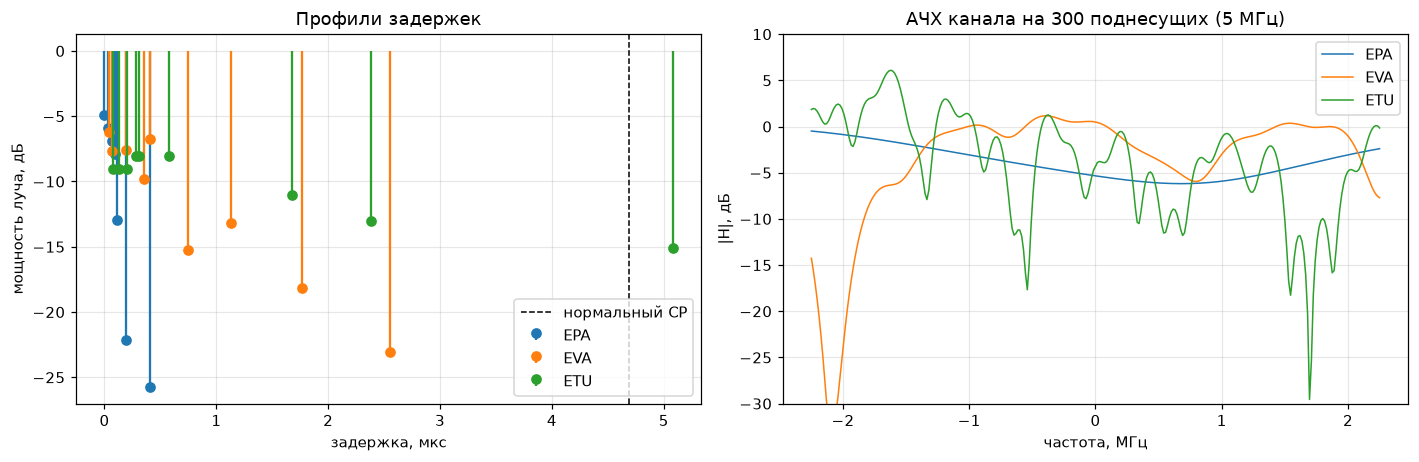

     | τ_max, мкс | τ_rms, нс | B_c, кГц | B_c/Δf | τ_max в отсчётах одной несущей 7.68 МГц
EPA  |      0.41  |       43  |    4637  | 309.1  | 3
EVA  |      2.51  |      357  |     561  |  37.4  | 19
ETU  |      5.00  |      991  |     202  |  13.5  | 38


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
f_sc = SC_IDX * DF / 1e6
rows = []
for i, name in enumerate(PROFILES):
    t, p = pdp(name)
    ax[0].stem(t * 1e6 + 0.04 * i, 10 * np.log10(p), linefmt=f"C{i}-", markerfmt=f"C{i}o", basefmt=" ", label=name)
    g = fading(name, 1, 0, np.random.default_rng(10 + i))[0]
    ax[1].plot(f_sc, 20 * np.log10(np.abs(freq_response(g, tap_delays(name)))), f"C{i}", lw=1, label=name)
    tr = tau_rms(name)
    rows.append((name, t.max() * 1e6, tr * 1e9, 1 / (5 * tr) / 1e3, t.max() * FS))
ax[0].axvline(CP[1] / FS * 1e6, color="k", ls="--", lw=1, label="нормальный CP")
ax[0].set_xlabel("задержка, мкс"); ax[0].set_ylabel("мощность луча, дБ"); ax[0].legend(); ax[0].set_title("Профили задержек")
ax[1].set_xlabel("частота, МГц"); ax[1].set_ylabel("|H|, дБ"); ax[1].set_ylim(-30, 10); ax[1].legend()
ax[1].set_title(f"АЧХ канала на {N_SC} поднесущих ({BW_MHZ} МГц)")
plt.tight_layout(); plt.show()

print(f"{'':4} | τ_max, мкс | τ_rms, нс | B_c, кГц | B_c/Δf | τ_max в отсчётах одной несущей {FS/1e6:.2f} МГц")
for name, tm, tr, bc, ns in rows:
    print(f"{name:4} | {tm:9.2f}  | {tr:8.0f}  | {bc:7.0f}  | {bc*1e3/DF:5.1f}  | {ns:.0f}")

## 2. OFDM-символ
Слева: спектр каждой поднесущей на интервале $T_u$ — это $\operatorname{sinc}\big((f-k\Delta f)/\Delta f\big)$. Спектры сильно перекрываются, но в точке $k\Delta f$ все соседи проходят через ноль — это и есть ортогональность, FFT берёт отсчёты именно там.

В центре — один символ во времени (вещественная часть) с CP: первые $N_\text{cp}$ отсчётов точно повторяют последние. Справа — спектр субкадра: занято $N_\text{SC}\cdot\Delta f$, остаток до $f_s$ — защитные полосы, в центре пустая DC-поднесущая (утечку гетеродина прямого преобразования она не портит).

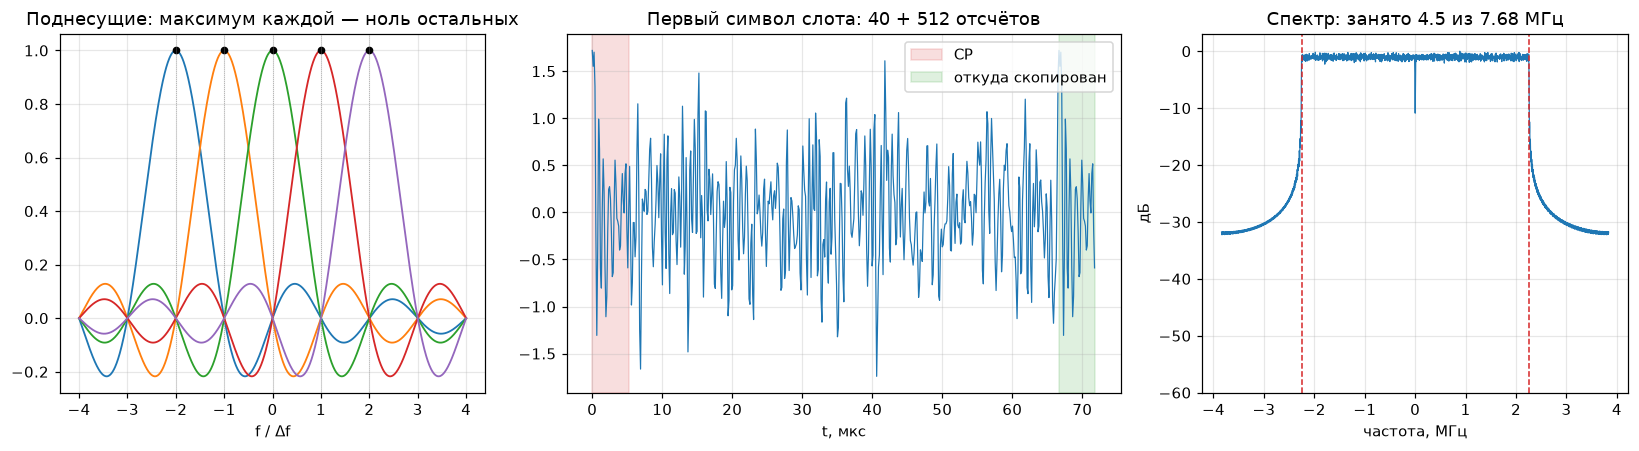

CP = копия хвоста: max|x[0:40] − x[512:552]| = 0.0e+00
Накладные расходы CP: 6.7% времени


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.3, 1]})
f = np.linspace(-4, 4, 1000)
for k in range(-2, 3):
    ax[0].plot(f, np.sinc(f - k), lw=1.2)
    ax[0].plot(k, 1, "ko", ms=4)
ax[0].set_xlabel("f / Δf"); ax[0].set_title("Поднесущие: максимум каждой — ноль остальных")
for k in range(-2, 3):
    ax[0].axvline(k, color="0.6", lw=0.5, ls=":")

q16 = QAM(4)
X = q16.mod(rng.integers(0, 2, (1, 14, 4 * N_SC)))
x = ofdm_mod(X)[0]
n1 = CP[0] + N_FFT
tt = np.arange(n1) / FS * 1e6
ax[1].plot(tt, x[:n1].real, "C0", lw=0.8)
ax[1].axvspan(0, CP[0] / FS * 1e6, color="C3", alpha=0.15, label="CP")
ax[1].axvspan(N_FFT / FS * 1e6, n1 / FS * 1e6, color="C2", alpha=0.15, label="откуда скопирован")
ax[1].set_xlabel("t, мкс"); ax[1].legend(loc="upper right"); ax[1].set_title(f"Первый символ слота: {CP[0]} + {N_FFT} отсчётов")

X = q16.mod(rng.integers(0, 2, (40, 14, 4 * N_SC)))
fw, P = welch(ofdm_mod(X).ravel(), FS, nperseg=2048, return_onesided=False)
o = np.argsort(fw)
ax[2].plot(fw[o] / 1e6, 10 * np.log10(P[o] / P.max()), lw=0.8)
for e in (-1, 1):
    ax[2].axvline(e * N_SC * DF / 2e6, color="C3", ls="--", lw=1)
ax[2].set_xlabel("частота, МГц"); ax[2].set_ylabel("дБ"); ax[2].set_ylim(-60, 3)
ax[2].set_title(f"Спектр: занято {N_SC*DF/1e6:.1f} из {FS/1e6:.2f} МГц")
plt.tight_layout(); plt.show()
print(f"CP = копия хвоста: max|x[0:{CP[0]}] − x[{N_FFT}:{n1}]| = {np.abs(ofdm_mod(X[:1])[0, :CP[0]] - ofdm_mod(X[:1])[0, N_FFT:n1]).max():.1e}")
print(f"Накладные расходы CP: {CP.sum() / (CP.sum() + 7 * N_FFT):.1%} времени")

## 3. Зачем CP: интерференция при коротком префиксе
Луч с задержкой $d_l$ отсчётов, $d_l>N_\text{cp}$, затаскивает в окно FFT $d_l-N_\text{cp}$ отсчётов **предыдущего** символа (ISI) и на столько же отсчётов теряет текущий — свёртка перестаёт быть циклической, поднесущие начинают протекать друг в друга (ICI). При независимых данных обе добавки — шумоподобные, и мощность помехи
$$P_\text{I}\approx\frac{2}{N}\sum_l p_l\,(d_l-N_\text{cp})^+$$
Ниже — без шума, с идеальным знанием $H_k$: всё, что остаётся после эквалайзера — помеха от канала. Справа — 16QAM через ETU без CP и с нормальным CP.

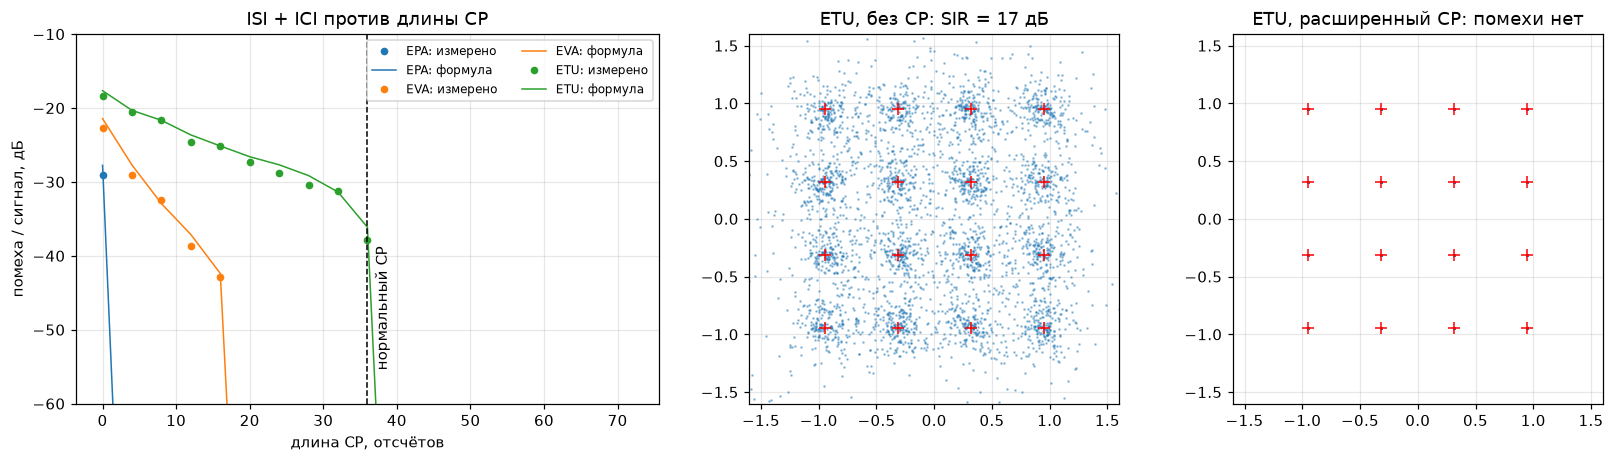

ETU: последний луч 38.4 отсчёта при CP = 36 — помеха -36 дБ, ниже шума в любом реальном сценарии; расширенный CP (16.7 мкс) — для больших сот и MBSFN


In [5]:
B, nsym = 40, 14
cps = np.arange(0, 73, 4)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
for i, name in enumerate(PROFILES):
    p = pdp(name)[1]; d = tap_delays(name)
    meas, th = [], []
    for c in cps:
        X = q16.mod(rng.integers(0, 2, (B, nsym, 4 * N_SC)))
        g = fading(name, 1, 0, rng, (B,))
        Y = ofdm_demod(apply_channel(ofdm_mod(X, [c]), g, d), nsym, [c])
        e = Y[:, 1:] - freq_response(g, d) * X[:, 1:]
        meas.append(np.mean(np.abs(e)**2)); th.append(2 * np.sum(p * np.clip(d - c, 0, None)) / N_FFT)
    ax[0].plot(cps, 10 * np.log10(np.maximum(meas, 1e-12)), f"C{i}o", ms=4, label=f"{name}: измерено")
    ax[0].plot(cps, 10 * np.log10(np.maximum(th, 1e-12)), f"C{i}-", lw=1, label=f"{name}: формула")
ax[0].axvline(CP[1], color="k", ls="--", lw=1); ax[0].text(CP[1] + 1, -55, "нормальный CP", rotation=90)
ax[0].set_ylim(-60, -10); ax[0].set_xlabel("длина CP, отсчётов"); ax[0].set_ylabel("помеха / сигнал, дБ")
ax[0].legend(fontsize=8, ncol=2); ax[0].set_title("ISI + ICI против длины CP")

g = fading("ETU", 1, 0, np.random.default_rng(5)); dE = tap_delays("ETU")
X = q16.mod(rng.integers(0, 2, (nsym, 4 * N_SC)))
H = freq_response(g, dE)
for a, c, title in [(ax[1], 0, "ETU, без CP"), (ax[2], CP_EXT, "ETU, расширенный CP")]:
    Z = ofdm_demod(apply_channel(ofdm_mod(X, [c]), g, dE), nsym, [c])[1:] / H
    a.plot(Z.real.ravel(), Z.imag.ravel(), ".", ms=1.5, alpha=0.4)
    a.plot(q16.const.real, q16.const.imag, "r+", ms=8)
    sir = 10 * np.log10(1 / np.mean(np.abs(Z - X[1:])**2 * np.abs(H)**2))
    a.set_title(f"{title}: SIR = {sir:.0f} дБ" if sir < 200 else f"{title}: помехи нет"); a.set_aspect("equal")
    a.set_xlim(-1.6, 1.6); a.set_ylim(-1.6, 1.6)
plt.tight_layout(); plt.show()
print(f"ETU: последний луч {pdp('ETU')[0].max()*FS:.1f} отсчёта при CP = {CP[1]} — "
      f"помеха {10*np.log10(2*np.sum(pdp('ETU')[1]*np.clip(dE-CP[1],0,None))/N_FFT):.0f} дБ, "
      "ниже шума в любом реальном сценарии; расширенный CP (16.7 мкс) — для больших сот и MBSFN")

## 4. Ресурсная сетка и оценка канала по CRS
Приёмник не знает $H_k$ — его измеряют по **опорным сигналам** (CRS, порт 0): в символах 0 и 4 каждого слота на каждой 6-й поднесущей (во втором — со сдвигом 3), сдвиг всей решётки $v_\text{shift}=N_\text{ID}^\text{cell}\bmod 6$, чтобы пилоты соседних сот не били друг в друга. Значения пилотов — QPSK из **Gold-последовательности длины 31** — того же семейства, что и коды GPS/CDMA в первом ноутбуке.

Оценка: LS на пилотах $\hat H_k=Y_k/P_k$ (ошибка = шум $N_0$), затем интерполяция. Это **дискретизация** $H(f,t)$: по теореме Котельникова шаг пилотов должен быть мельче полосы когерентности и времени когерентности:
- по частоте: шаг 6 поднесущих = 90 кГц → без наложения $\tau_\text{max}<1/90\,\text{кГц}=11$ мкс;
- по времени: шаг ~0.21–0.29 мс → $f_D<1/(2\cdot0.29\,\text{мс})\approx1.7$ кГц, на 2 ГГц это ~900 км/ч.

Линейная интерполяция грубее теоремы, и у ETU по частоте она уже ошибается (канал меняется заметно между пилотами).

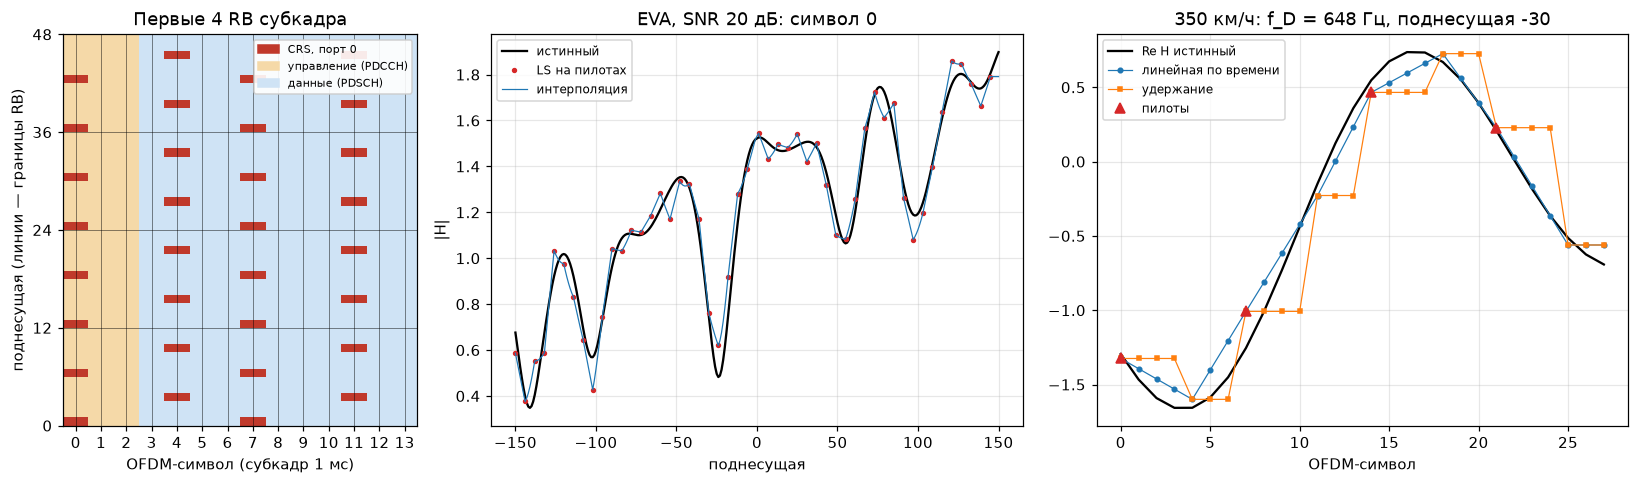

MSE оценки канала, дБ (шум на пилоте N0 = -20 дБ):
     |    3 км/ч lin  hold |  120 км/ч lin  hold |  350 км/ч lin  hold 


EPA  |       -23.1  -21.7 |       -22.1  -16.8 |       -17.4   -9.4 


EVA  |       -22.7  -21.3 |       -21.8  -16.6 |       -17.7   -9.6 


ETU  |       -17.8  -16.9 |       -17.2  -14.4 |       -15.2   -8.8 


In [6]:
M, V = crs_grid(14)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [0.8, 1.2, 1.2]})
G = np.zeros((14, N_SC)); G[:3] = 1; G[M] = 2
ax[0].imshow(G[:, :48].T, origin="lower", aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#cfe3f5", "#f5d9a8", "#c0392b"]),
             extent=[-0.5, 13.5, -0.5, 47.5])
ax[0].set_xticks(range(14)); ax[0].set_yticks(np.arange(0, 49, 12) - 0.5, [str(v) for v in range(0, 49, 12)])
ax[0].grid(True, color="k", lw=0.6, alpha=0.5)
ax[0].legend(handles=[plt.matplotlib.patches.Patch(color=c, label=l) for c, l in
                      [("#c0392b", "CRS, порт 0"), ("#f5d9a8", "управление (PDCCH)"), ("#cfe3f5", "данные (PDSCH)")]],
             loc="upper right", fontsize=7, framealpha=0.9)
ax[0].set_xlabel("OFDM-символ (субкадр 1 мс)"); ax[0].set_ylabel("поднесущая (линии — границы RB)"); ax[0].set_title("Первые 4 RB субкадра")

q4 = QAM(2)
fd = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
n0 = 10 ** (-SNR_DB / 10)
nsym = 28
M2, V2 = crs_grid(nsym)
def run_subframes(name, fd, B, nsym=nsym, rng=rng):
    X = np.where(M2, V2, q4.mod(rng.integers(0, 2, (B, nsym, 2 * N_SC))))
    x = ofdm_mod(X); g = fading(name, x.shape[-1], fd, rng, (B,)); d = tap_delays(name)
    Y = ofdm_demod(apply_channel(x, g, d) + awgn(x.shape, n0, rng), nsym)
    Ht = freq_response(g[:, sym_starts(nsym) + N_FFT // 2], d)     # истинный H в середине символа
    return X, Y, Ht

X, Y, Ht = run_subframes(PROFILE, fd, 1, rng=np.random.default_rng(7))
He = chan_est(Y, V2, M2)
s = 0; kk = np.nonzero(M2[s])[0]
ax[1].plot(SC_IDX, np.abs(Ht[0, s]), "k", lw=1.5, label="истинный")
ax[1].plot(SC_IDX[kk], np.abs(Y[0, s, kk] / V2[s, kk]), "C3.", ms=5, label="LS на пилотах")
ax[1].plot(SC_IDX, np.abs(He[0, s]), "C0", lw=0.8, label="интерполяция")
ax[1].set_xlabel("поднесущая"); ax[1].set_ylabel("|H|"); ax[1].legend(fontsize=8)
ax[1].set_title(f"{PROFILE}, SNR {SNR_DB} дБ: символ 0")

Xf, Yf, Htf = run_subframes(PROFILE, 350 / 3.6 * FC_GHZ * 1e9 / 3e8, 1, rng=np.random.default_rng(8))
k0 = np.nonzero(M2[0])[0][20]
ps = np.nonzero(M2[:, k0])[0]
ax[2].plot(np.arange(nsym), Htf[0, :, k0].real, "k", lw=1.5, label="Re H истинный")
ax[2].plot(np.arange(nsym), chan_est(Yf, V2, M2)[0, :, k0].real, "C0o-", ms=3, lw=0.8, label="линейная по времени")
ax[2].plot(np.arange(nsym), chan_est(Yf, V2, M2, "hold")[0, :, k0].real, "C1s-", ms=3, lw=0.8, label="удержание")
ax[2].plot(ps, (Yf[0, ps, k0] / V2[ps, k0]).real, "C3^", ms=7, label="пилоты")
ax[2].set_xlabel("OFDM-символ"); ax[2].legend(fontsize=8)
ax[2].set_title(f"350 км/ч: f_D = {350/3.6*FC_GHZ*1e9/3e8:.0f} Гц, поднесущая {SC_IDX[k0]}")
plt.tight_layout(); plt.show()

print(f"MSE оценки канала, дБ (шум на пилоте N0 = {10*np.log10(n0):.0f} дБ):")
print(f"{'':5}" + "".join(f"| {v:>4} км/ч lin  hold " for v in (3, 120, 350)))
for name in PROFILES:
    line = f"{name:5}"
    for v in (3, 120, 350):
        _, Yb, Htb = run_subframes(name, v / 3.6 * FC_GHZ * 1e9 / 3e8, 30)
        e = [10 * np.log10(np.mean(np.abs(chan_est(Yb, V2, M2, m) - Htb)**2)) for m in ("linear", "hold")]
        line += f"|      {e[0]:6.1f} {e[1]:6.1f} "
    print(line)

## 5. Доплер: поднесущие перестают быть ортогональными
Пока канал меняется внутри одного символа $T_u$, на окне FFT это уже не умножение на константу: поднесущая расплывается в соседей. Для модели Джейкса (равномерные углы прихода) мощность ICI относительно сигнала:
$$P_\text{ICI}=1-\frac1{N^2}\sum_{n,m}J_0\!\big(2\pi f_D T_u\,\tfrac{n-m}{N}\big)\approx\frac{(\pi f_DT_u)^2}{6}$$
Отсюда и 15 кГц: поднесущая должна быть шире доплера **с запасом** (ICI) и уже полосы когерентности (плоский канал). На 2 ГГц и 350 км/ч $f_DT_u\approx0.04$, ICI ≈ −25 дБ — для QPSK/16QAM не ограничивает; ограничивает отслеживание канала из раздела 4.

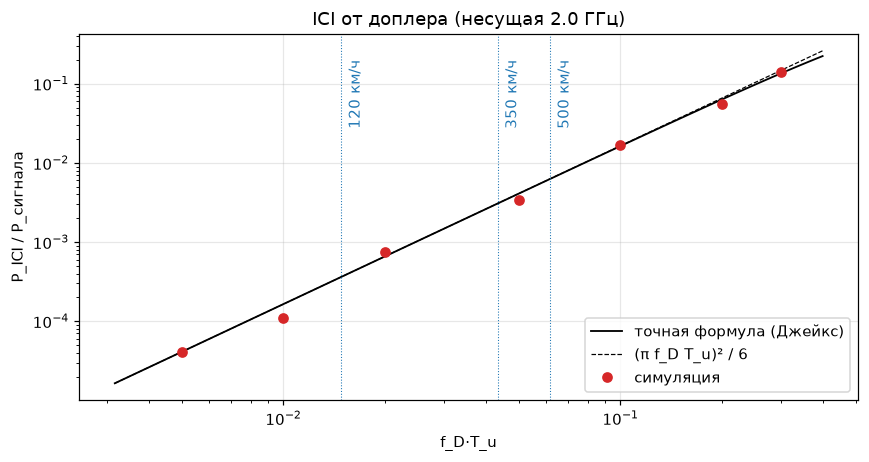

f_D·T_u = 0.005 (f_D =     75 Гц): ICI измерено  -43.9 дБ, теория  -43.9 дБ
f_D·T_u = 0.010 (f_D =    150 Гц): ICI измерено  -39.6 дБ, теория  -37.8 дБ
f_D·T_u = 0.020 (f_D =    300 Гц): ICI измерено  -31.3 дБ, теория  -31.8 дБ
f_D·T_u = 0.050 (f_D =    750 Гц): ICI измерено  -24.6 дБ, теория  -23.9 дБ
f_D·T_u = 0.100 (f_D =   1500 Гц): ICI измерено  -17.8 дБ, теория  -17.9 дБ
f_D·T_u = 0.200 (f_D =   3000 Гц): ICI измерено  -12.5 дБ, теория  -12.0 дБ
f_D·T_u = 0.300 (f_D =   4500 Гц): ICI измерено   -8.5 дБ, теория   -8.7 дБ


In [7]:
def ici_theory(fdT):
    n = np.arange(-N_FFT + 1, N_FFT)
    return 1 - np.sum((N_FFT - np.abs(n)) / N_FFT**2 * j0(2 * np.pi * fdT * n / N_FFT))

fdTs = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3])
meas = []
for fdT in fdTs:
    B = 30
    X = q4.mod(rng.integers(0, 2, (B, 14, 2 * N_SC))); x = ofdm_mod(X)
    g = fading("EPA", x.shape[-1], fdT / T_U, rng, (B,), n_sin=32); d = tap_delays("EPA")
    Y = ofdm_demod(apply_channel(x, g, d), 14)
    Hm = np.stack([freq_response(g[:, p:p + N_FFT].mean(1), d) for p in sym_starts(14)], 1)   # «полезная» часть
    meas.append(np.mean(np.abs(Y - Hm * X)**2))
fg = np.logspace(-2.5, -0.4, 100)
fig, a = plt.subplots(figsize=(8, 4.3))
a.loglog(fg, [ici_theory(v) for v in fg], "k", lw=1.2, label="точная формула (Джейкс)")
a.loglog(fg, (np.pi * fg)**2 / 6, "k--", lw=0.8, label="(π f_D T_u)² / 6")
a.loglog(fdTs, meas, "C3o", label="симуляция")
for v in (120, 350, 500):
    fv = v / 3.6 * FC_GHZ * 1e9 / 3e8 * T_U
    a.axvline(fv, color="C0", lw=0.7, ls=":"); a.text(fv * 1.05, 3e-2, f"{v} км/ч", color="C0", rotation=90)
a.set_xlabel("f_D·T_u"); a.set_ylabel("P_ICI / P_сигнала"); a.legend(); a.set_title(f"ICI от доплера (несущая {FC_GHZ} ГГц)")
plt.tight_layout(); plt.show()
for fdT, m in zip(fdTs, meas):
    print(f"f_D·T_u = {fdT:5.3f} (f_D = {fdT/T_U:6.0f} Гц): ICI измерено {10*np.log10(m):6.1f} дБ, теория {10*np.log10(ici_theory(fdT)):6.1f} дБ")

## 6. Модуляция и BER без кода: AWGN против замираний
LTE адаптирует модуляцию к каналу: QPSK / 16QAM / 64QAM (в Rel-12 и 256QAM) — 2/4/6 бит на ресурсный элемент. В AWGN BER падает экспоненциально с SNR. На поднесущей с релеевским замиранием мгновенный SNR $\gamma$ распределён экспоненциально, и среднее
$$\overline{P_b}=\int_0^\infty P_b^\text{AWGN}(\gamma)\,\frac{e^{-\gamma/\bar\gamma}}{\bar\gamma}\,d\gamma\;\propto\;\frac1{\bar\gamma}$$
— каждые 10 дБ дают лишь порядок. BER определяют поднесущие, попавшие в глубокий провал. Эквалайзер с ними ничего не сделает — шум делится на $|H_k|^2\approx0$. Ниже: идеальное знание канала, $H_k$ — из модели `PROFILE` во времени (полная OFDM-цепочка).

64QAM, BER = 1e-3: AWGN 22.5 дБ, Рэлей 37.8 дБ — замирание стоит 15 дБ, и каждые следующие 10 дБ дают только порядок


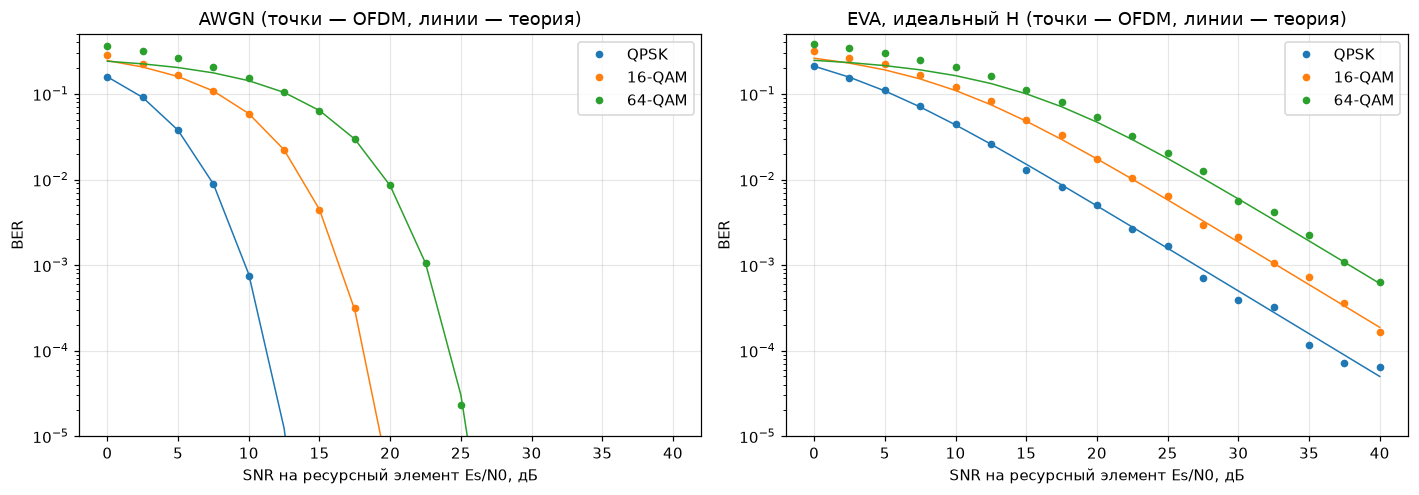

In [8]:
snrs = np.arange(0, 41, 2.5)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
B, nsym = 300, 2                     # много независимых реализаций канала, по 2 символа на каждую
for i, Q in enumerate((2, 4, 6)):
    q = QAM(Q); ra, rf = [], []
    for snr in snrs:
        n0 = 10 ** (-snr / 10)
        bits = rng.integers(0, 2, (B, nsym, Q * N_SC)); X = q.mod(bits); x = ofdm_mod(X)
        Y = ofdm_demod(x + awgn(x.shape, n0, rng), nsym)
        ra.append(np.mean(q.hard(Y) != bits))
        g = fading(PROFILE, 1, 0, rng, (B,)); d = tap_delays(PROFILE)
        Y = ofdm_demod(apply_channel(x, g, d) + awgn(x.shape, n0, rng), nsym)
        rf.append(np.mean(q.hard(Y / freq_response(g, d)) != bits))
    g = 10 ** (snrs / 10)
    ax[0].semilogy(snrs, ber_awgn(Q, g), f"C{i}-", lw=1); ax[0].semilogy(snrs, ra, f"C{i}o", ms=4, label=f"{2**Q}-QAM" if Q > 2 else "QPSK")
    ax[1].semilogy(snrs, ber_rayleigh(Q, g), f"C{i}-", lw=1); ax[1].semilogy(snrs, rf, f"C{i}o", ms=4, label=f"{2**Q}-QAM" if Q > 2 else "QPSK")
    if Q == 6:
        thr = lambda f: brentq(lambda s: np.log10(np.maximum(f(10**(s / 10)), 1e-300)) + 3, 0, 50)
        print(f"64QAM, BER = 1e-3: AWGN {thr(lambda g: ber_awgn(6, g)):.1f} дБ, Рэлей {thr(lambda g: ber_rayleigh(6, g)):.1f} дБ "
              "— замирание стоит 15 дБ, и каждые следующие 10 дБ дают только порядок")
for a, t in zip(ax, ["AWGN", f"{PROFILE}, идеальный H"]):
    a.set_ylim(1e-5, 0.5); a.set_xlabel("SNR на ресурсный элемент Es/N0, дБ"); a.set_ylabel("BER"); a.legend(); a.set_title(t + " (точки — OFDM, линии — теория)")
plt.tight_layout(); plt.show()

## 7. Турбокод LTE
Два одинаковых **рекурсивных** свёрточных кодера (RSC, 8 состояний, $G=[1,\ 15_8/13_8]$): первый видит биты по порядку, второй — переставленные QPP-перемежителем $\Pi(i)=(f_1i+f_2i^2)\bmod K$. Выход: систематика + две проверки, $R=1/3$, плюс 12 хвостовых бит, возвращающих оба кодера в нулевое состояние. Рекурсивность важна: одиночная единица на входе порождает бесконечный отклик, поэтому слова малого веса возникают, только если перемежитель «неудачно» сведёт веса обоих кодеров, — что QPP делает редкостью.

Декодер — та же идея, что BP в LDPC, только узлов два: каждый **BCJR** (MAP по решётке, прямой–обратный проход) получает канальные LLR и априорную информацию от соседа, а отдаёт только **внешнюю** часть
$$L_e=L_\text{post}-L_\text{ch}-L_a,$$
чтобы не возвращать соседу его же сведения. **log-MAP** считает $\max^*(a,b)=\max(a,b)+\ln(1+e^{-|a-b|})$ точно; **max-log-MAP** выбрасывает поправку (железо любит) и теряет несколько десятых дБ; масштаб 0.7 на $L_e$ возвращает часть — аналог нормировки в min-sum.

Слева — водопад в AWGN (BPSK) для $K$ = `K_TURBO`, пунктир — предел Шеннона для двоичного входа при $R=1/3$. Справа — BER после каждой итерации log-MAP.

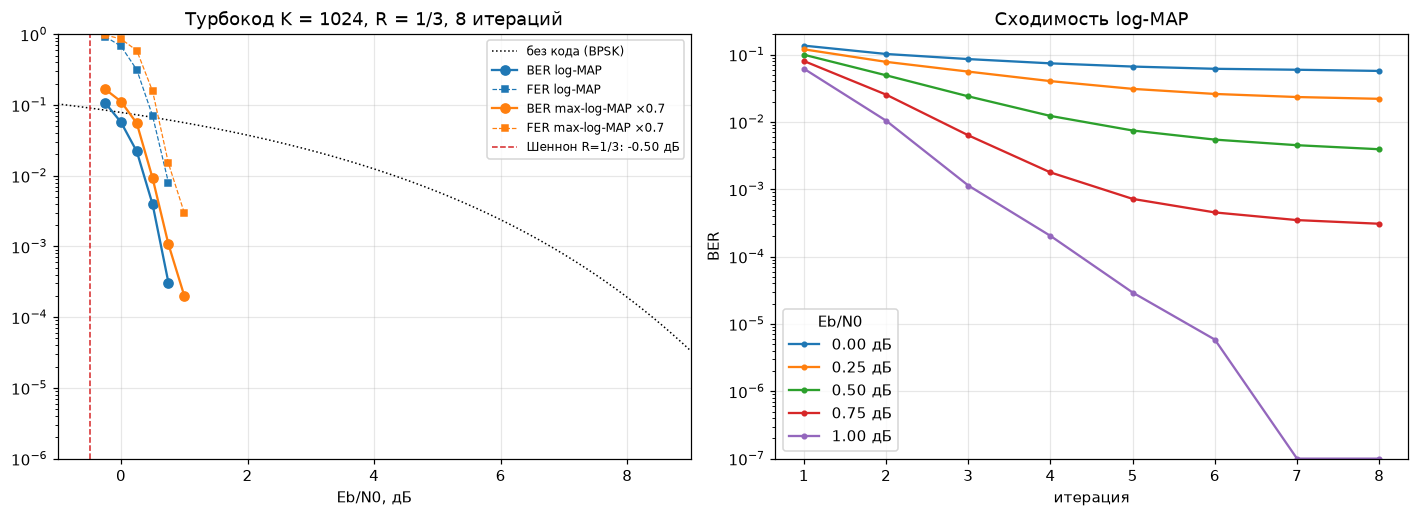

 Eb/N0 | BER log-MAP  FER  | BER max-log  FER  | кадров
 -0.25 |  1.1e-01  0.930 |  1.7e-01   0.980 | 100/100
  0.00 |  5.7e-02  0.680 |  1.1e-01   0.860 | 100/100
  0.25 |  2.2e-02  0.315 |  5.5e-02   0.590 | 200/100
  0.50 |  3.9e-03  0.070 |  9.2e-03   0.157 | 700/300
  0.75 |  3.1e-04  0.008 |  1.1e-03   0.015 | 1000/1000
  1.00 |  0.0e+00  0.000 |  2.0e-04   0.003 | 1000/1000
  1.25 |  0.0e+00  0.000 |  0.0e+00   0.000 | 1000/1000


In [9]:
def biawgn_limit(R):
    """Eb/N0 (дБ), при котором ёмкость BPSK-AWGN равна R."""
    def cap(ebn0_db):
        s2 = 1 / (2 * R * 10 ** (ebn0_db / 10)); mu = 2 / s2
        f = lambda l: np.log2(1 + np.exp(-l)) * np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu)
        return 1 - quad(f, mu - 40 * np.sqrt(mu), mu + 40 * np.sqrt(mu))[0]
    return brentq(lambda e: cap(e) - R, -2, 5)

def simulate_turbo(ebn0_list, K, exact, punct=None, min_fe=40, max_frames=2000, batch=100, track=False):
    res, it_ber = [], []
    for e in ebn0_list:
        be = fe = nf = 0; per_it = np.zeros(TURBO_ITERS)
        while fe < min_fe and nf < max_frames:
            u = rng.integers(0, 2, (batch, K)); c = turbo_encode(u)
            m = np.ones(c.shape[1], bool) if punct is None else punct
            R = K / m.sum(); s2 = 1 / (2 * R * 10 ** (e / 10))
            L = np.zeros(c.shape); L[:, m] = 2 * ((1 - 2 * c[:, m]) + np.sqrt(s2) * rng.standard_normal((batch, m.sum()))) / s2
            def cb(it, Lp): per_it[it] += np.sum((Lp < 0) != u)
            uh = turbo_decode(L, K, exact=exact, cb=cb if track else None)
            err = uh != u; be += err.sum(); fe += err.any(1).sum(); nf += batch
        res.append((be / (nf * K), fe / nf, nf)); it_ber.append(per_it / (nf * K))
    return np.array(res), np.array(it_ber)

ebn0 = np.arange(-0.25, 1.26, 0.25)
r_log, it_log = simulate_turbo(ebn0, K_TURBO, True, track=True, max_frames=1000)
r_max, _ = simulate_turbo(ebn0, K_TURBO, False, max_frames=1000)
R3 = K_TURBO / (3 * K_TURBO + 12)
lim3 = biawgn_limit(1 / 3)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
eg = np.linspace(-1, 9, 200)
ax[0].semilogy(eg, 0.5 * erfc(np.sqrt(10 ** (eg / 10))), "k:", lw=1, label="без кода (BPSK)")
for r, lab, c in [(r_log, "log-MAP", "C0"), (r_max, "max-log-MAP ×0.7", "C1")]:
    ok = r[:, 0] > 0
    ax[0].semilogy(ebn0[ok], r[ok, 0], c + "o-", label=f"BER {lab}")
    ax[0].semilogy(ebn0[r[:, 1] > 0], r[r[:, 1] > 0, 1], c + "s--", ms=4, lw=0.8, label=f"FER {lab}")
ax[0].axvline(lim3, color="C3", ls="--", lw=1, label=f"Шеннон R=1/3: {lim3:.2f} дБ")
ax[0].set_xlim(-1, 9); ax[0].set_ylim(1e-6, 1); ax[0].set_xlabel("Eb/N0, дБ"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Турбокод K = {K_TURBO}, R = 1/3, {TURBO_ITERS} итераций")
for j, e in enumerate(ebn0):
    if 0 <= e <= 1.0:
        ax[1].semilogy(np.arange(1, TURBO_ITERS + 1), np.maximum(it_log[j], 1e-7), "o-", ms=3, label=f"{e:.2f} дБ")
ax[1].set_xlabel("итерация"); ax[1].set_ylabel("BER"); ax[1].set_ylim(1e-7, 0.2); ax[1].legend(title="Eb/N0")
ax[1].set_title("Сходимость log-MAP")
plt.tight_layout(); plt.show()

print(" Eb/N0 | BER log-MAP  FER  | BER max-log  FER  | кадров")
for e, a, b in zip(ebn0, r_log, r_max):
    print(f" {e:5.2f} |  {a[0]:.1e}  {a[1]:.3f} |  {b[0]:.1e}   {b[1]:.3f} | {int(a[2])}/{int(b[2])}")

### Турбо против LDPC при одинаковых $R$ и $n$
Чтобы сравнить с регулярным LDPC (3,6) из соседнего ноутбука ($R=1/2$, $n=1008$, BER $10^{-4}$ при ≈2.3 дБ), берём $K=512$ и выкалываем половину проверочных бит: $n=1036$, $R\approx1/2$.

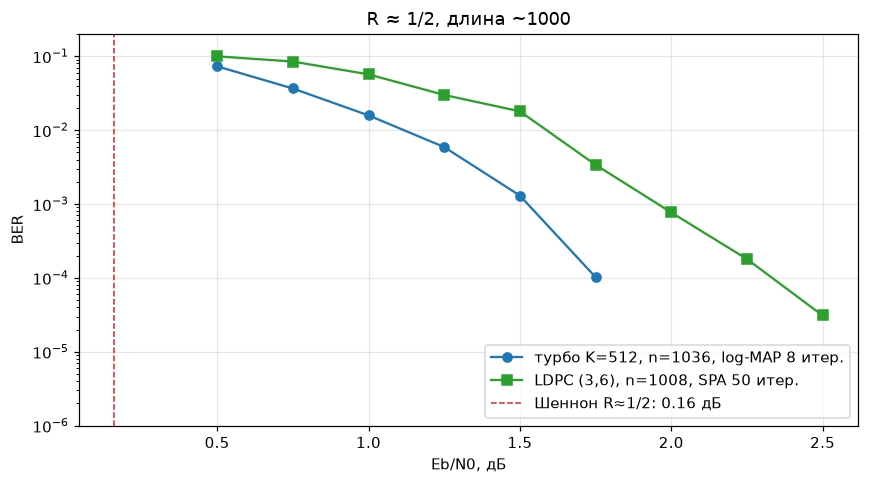

Eb/N0 0.50 дБ: турбо BER 7.3e-02 FER 0.750 (200 кадров) | LDPC (3,6) BER 1.0e-01
Eb/N0 0.75 дБ: турбо BER 3.7e-02 FER 0.475 (200 кадров) | LDPC (3,6) BER 8.5e-02
Eb/N0 1.00 дБ: турбо BER 1.6e-02 FER 0.220 (200 кадров) | LDPC (3,6) BER 5.7e-02
Eb/N0 1.25 дБ: турбо BER 5.9e-03 FER 0.090 (600 кадров) | LDPC (3,6) BER 3.0e-02
Eb/N0 1.50 дБ: турбо BER 1.3e-03 FER 0.022 (1800 кадров) | LDPC (3,6) BER 1.8e-02
Eb/N0 1.75 дБ: турбо BER 1.0e-04 FER 0.003 (2000 кадров) | LDPC (3,6) BER 3.4e-03
Eb/N0 2.00 дБ: турбо BER 0.0e+00 FER 0.000 (2000 кадров) | LDPC (3,6) BER 7.7e-04


In [10]:
K2 = 512
pm = puncture_half(K2)
ebn0_2 = np.arange(0.5, 2.01, 0.25)
r_p, _ = simulate_turbo(ebn0_2, K2, True, punct=pm, batch=200, max_frames=2000)
ldpc = {0.5: 1.0e-01, 0.75: 8.5e-02, 1.0: 5.7e-02, 1.25: 3.0e-02, 1.5: 1.8e-02, 1.75: 3.4e-03,
        2.0: 7.7e-04, 2.25: 1.8e-04, 2.5: 3.1e-05}         # SPA, 50 итераций — таблица из ldpc_sim.ipynb
lim2 = biawgn_limit(K2 / pm.sum())
fig, a = plt.subplots(figsize=(8, 4.5))
ok = r_p[:, 0] > 0
a.semilogy(ebn0_2[ok], r_p[ok, 0], "C0o-", label=f"турбо K={K2}, n={pm.sum()}, log-MAP {TURBO_ITERS} итер.")
a.semilogy(list(ldpc), list(ldpc.values()), "C2s-", label="LDPC (3,6), n=1008, SPA 50 итер.")
a.axvline(lim2, color="C3", ls="--", lw=1, label=f"Шеннон R≈1/2: {lim2:.2f} дБ")
a.set_xlabel("Eb/N0, дБ"); a.set_ylabel("BER"); a.set_ylim(1e-6, 0.2); a.legend(); a.set_title("R ≈ 1/2, длина ~1000")
plt.tight_layout(); plt.show()
for e, r in zip(ebn0_2, r_p):
    print(f"Eb/N0 {e:.2f} дБ: турбо BER {r[0]:.1e} FER {r[1]:.3f} ({int(r[2])} кадров) | LDPC (3,6) BER {ldpc.get(e, float('nan')):.1e}")

## 8. Код + OFDM: частотное разнесение
Главный трюк LTE на нисходящем канале: кодовое слово раскладывается по **всей полосе** (частота сначала, потом время). Поднесущие в провалах дают LLR ≈ 0 — для декодера это стирания, и он восстанавливает их по проверкам с поднесущих в хорошей фазе. Если же блок сидит в узкой полосе $\ll B_c$ (2 RB = 360 кГц), все его символы замирают **вместе**, и никакой код не спасёт кадр, попавший в провал: наклон кривой снова $1/\bar\gamma$, как без кода.

Порядок разнесения ≈ число независимо замирающих кусков полосы, $\sim N_\text{SC}\Delta f/B_c$. QPSK, $K$ = `K_TURBO`, $R=1/3$, канал `PROFILE` статичен на время блока, идеальное знание $H$, декодер max-log-MAP.

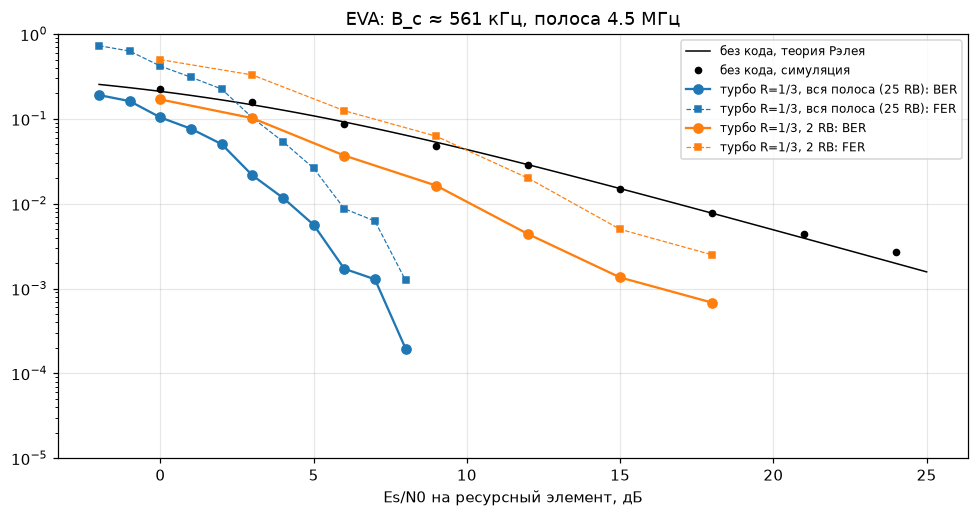

вся полоса (25 RB)   SNR  -2 дБ: BER 1.9e-01  FER 0.730
вся полоса (25 RB)   SNR  -1 дБ: BER 1.6e-01  FER 0.630
вся полоса (25 RB)   SNR   0 дБ: BER 1.0e-01  FER 0.420
вся полоса (25 RB)   SNR   1 дБ: BER 7.7e-02  FER 0.310
вся полоса (25 RB)   SNR   2 дБ: BER 5.0e-02  FER 0.225
вся полоса (25 RB)   SNR   3 дБ: BER 2.2e-02  FER 0.103
вся полоса (25 RB)   SNR   4 дБ: BER 1.2e-02  FER 0.054
вся полоса (25 RB)   SNR   5 дБ: BER 5.7e-03  FER 0.026
вся полоса (25 RB)   SNR   6 дБ: BER 1.7e-03  FER 0.009
вся полоса (25 RB)   SNR   7 дБ: BER 1.3e-03  FER 0.006
вся полоса (25 RB)   SNR   8 дБ: BER 2.0e-04  FER 0.001

2 RB                 SNR   0 дБ: BER 1.7e-01  FER 0.500
2 RB                 SNR   3 дБ: BER 1.0e-01  FER 0.330
2 RB                 SNR   6 дБ: BER 3.7e-02  FER 0.125
2 RB                 SNR   9 дБ: BER 1.6e-02  FER 0.062
2 RB                 SNR  12 дБ: BER 4.4e-03  FER 0.020
2 RB                 SNR  15 дБ: BER 1.4e-03  FER 0.005
2 RB                 SNR  18 дБ: BER 6.8e-04  F

In [11]:
def coded_ofdm_batch(snr_db, nsc, B, name=PROFILE, K=K_TURBO):
    u = rng.integers(0, 2, (B, K)); c = turbo_encode(u)
    perm = rng.permutation(c.shape[1])                           # канальный перемежитель
    s = q4.mod(c[:, perm]); nre = s.shape[1]; nsym = -(-nre // nsc)
    H = freq_response(fading(name, 1, 0, rng, (B,))[:, 0], tap_delays(name))
    k0 = rng.integers(0, N_SC - nsc + 1, B)
    Hk = np.stack([np.tile(H[b, k0[b]:k0[b] + nsc], nsym)[:nre] for b in range(B)])   # частота сначала
    n0 = 10 ** (-snr_db / 10)
    y = Hk * s + awgn(s.shape, n0, rng)
    z = y / Hk
    L = np.empty(c.shape); L[:, perm] = q4.llr(z, n0 / np.abs(Hk)**2)
    uh = turbo_decode(L, K, exact=False)                          # max-log: здесь важна форма кривой, а не десятые дБ
    return (uh != u).sum(), (uh != u).any(1).sum(), (q4.hard(z) != c[:, perm]).mean()

def coded_ofdm(snr_db, nsc, min_fe=25, max_frames=800, batch=100):
    be = fe = nf = 0; unc = []
    while fe < min_fe and nf < max_frames:
        b, f, uc = coded_ofdm_batch(snr_db, nsc, batch); be += b; fe += f; nf += batch; unc.append(uc)
    return be / (nf * K_TURBO), fe / nf, np.mean(unc)

allocs = {f"вся полоса ({N_RB} RB)": (N_SC, np.arange(-2, 9, 1)), "2 RB": (24, np.arange(0, 25, 3))}
res8 = {k: np.array([coded_ofdm(s, n) for s in sn]) for k, (n, sn) in allocs.items()}
fig, a = plt.subplots(figsize=(9, 4.8))
sg = np.arange(-2, 25.1, 0.5)
sn2 = allocs["2 RB"][1]
a.semilogy(sg, ber_rayleigh(2, 10 ** (sg / 10)), "k-", lw=1, label="без кода, теория Рэлея")
a.semilogy(sn2, res8["2 RB"][:, 2], "ko", ms=4, label="без кода, симуляция")
for i, (k, r) in enumerate(res8.items()):
    sn = allocs[k][1]
    ok = r[:, 0] > 0
    a.semilogy(sn[ok], r[ok, 0], f"C{i}o-", label=f"турбо R=1/3, {k}: BER")
    ok = r[:, 1] > 0
    a.semilogy(sn[ok], r[ok, 1], f"C{i}s--", ms=4, lw=0.8, label=f"турбо R=1/3, {k}: FER")
a.set_ylim(1e-5, 1); a.set_xlabel("Es/N0 на ресурсный элемент, дБ"); a.legend(fontsize=8)
a.set_title(f"{PROFILE}: B_c ≈ {1/(5*tau_rms(PROFILE))/1e3:.0f} кГц, полоса {N_SC*DF/1e6:.1f} МГц")
plt.tight_layout(); plt.show()
for k, r in res8.items():
    sn = allocs[k][1]
    for e, rr in zip(sn, r):
        print(f"{k:20} SNR {e:3d} дБ: BER {rr[0]:.1e}  FER {rr[1]:.3f}")
    print()

## 9. PAPR: почему на аплинке не чистый OFDM
Сумма сотен поднесущих со случайными фазами по ЦПТ — комплексный гауссов процесс: $|x|^2$ экспоненциален, и пик-фактор $\text{PAPR}=\max|x|^2/\overline{|x|^2}$ велик. Для $N$ независимых отсчётов
$$P(\text{PAPR}>z)\approx1-\big(1-e^{-z}\big)^{N}$$
Кривая — для $N$ независимых отсчётов; при передискретизации между ними есть ещё пики, поэтому измеренный OFDM правее на ~0.5 дБ.

Усилитель телефона должен оставаться линейным на пиках → большой back-off, низкий КПД, батарея. Поэтому на аплинке LTE — **SC-FDMA**: перед IFFT символы проходят через DFT размера $M$ (DFT-spread OFDM). Сигнал остаётся «одной несущей» с сохранением CP и эквалайзера по частоте, но огибающая — как у QPSK. Измерено с 4× передискретизацией (иначе пики между отсчётами теряются).

OFDM, QPSK     : PAPR, превышаемый в 0.1 % символов: 11.3 дБ


OFDM, 64QAM    : PAPR, превышаемый в 0.1 % символов: 11.4 дБ
SC-FDMA, QPSK  : PAPR, превышаемый в 0.1 % символов: 8.1 дБ


SC-FDMA, 16QAM : PAPR, превышаемый в 0.1 % символов: 9.2 дБ


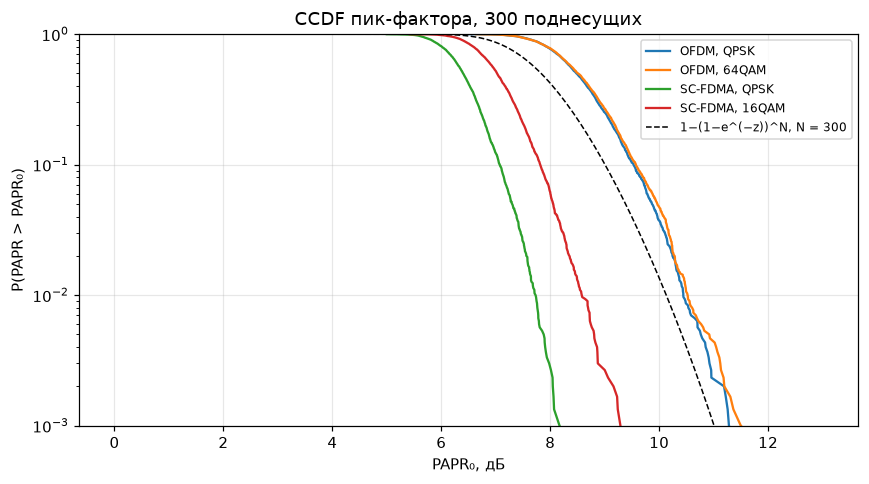

In [12]:
OS, Mu, B = 4, N_SC, 3000
def papr(X, os=OS):
    G = np.zeros((len(X), N_FFT * os), complex); G[:, SC_IDX % (N_FFT * os)] = X
    x = np.fft.ifft(G, axis=1)
    p = np.abs(x)**2
    return 10 * np.log10(p.max(1) / p.mean(1))
fig, a = plt.subplots(figsize=(8, 4.5))
zz = np.linspace(0, 13, 200)
cases = {"OFDM, QPSK": QAM(2).mod(rng.integers(0, 2, (B, 2 * Mu))),
         "OFDM, 64QAM": QAM(6).mod(rng.integers(0, 2, (B, 6 * Mu))),
         "SC-FDMA, QPSK": np.fft.fft(QAM(2).mod(rng.integers(0, 2, (B, 2 * Mu))), axis=1) / np.sqrt(Mu),
         "SC-FDMA, 16QAM": np.fft.fft(QAM(4).mod(rng.integers(0, 2, (B, 4 * Mu))), axis=1) / np.sqrt(Mu)}
for i, (k, X) in enumerate(cases.items()):
    p = np.sort(papr(X))
    a.semilogy(p, 1 - np.arange(B) / B, f"C{i}", lw=1.5, label=k)
    print(f"{k:15}: PAPR, превышаемый в 0.1 % символов: {np.quantile(p, 0.999):.1f} дБ")
a.semilogy(zz, 1 - (1 - np.exp(-10 ** (zz / 10)))**N_SC, "k--", lw=1, label=f"1−(1−e^(−z))^N, N = {N_SC}")
a.set_ylim(1e-3, 1); a.set_xlabel("PAPR₀, дБ"); a.set_ylabel("P(PAPR > PAPR₀)"); a.legend(fontsize=8)
a.set_title(f"CCDF пик-фактора, {N_SC} поднесущих")
plt.tight_layout(); plt.show()

## Сравнение с CDMA и LDPC
3G (WCDMA) и 4G (LTE) решают одну задачу — широкая полоса в многолучевом канале — с противоположных сторон.

| | CDMA / WCDMA | OFDM / LTE |
|---|---|---|
| Многолучёвость | RAKE: каждый луч — отдельный «палец», когерентно складываются | CP + одно деление на поднесущую |
| Сложность эквалайзера | растёт с числом лучей и полосой | FFT: $O(N\log N)$, от канала не зависит |
| Разнесение | лучи в RAKE (по времени) | код по поднесущим (по частоте) |
| Множественный доступ | коды, все в одной полосе, борьба «ближний–дальний», быстрый контроль мощности | ресурсные блоки, ортогональны внутри соты |
| Пик-фактор | низкий | высокий → SC-FDMA на аплинке |
| Чувствительность к частоте | слабая | доплер / сдвиг частоты → ICI, нужна точная синхронизация |

Код: в LTE — турбо (два свёрточных кода + QPP), в 5G NR для данных — квазициклический LDPC. Оба — итеративный обмен **внешними** LLR. При $n\approx1000$ и $R=1/2$ турбокод здесь лучше регулярного (3,6) LDPC: у регулярного кода порог плохой (1.1 дБ против 0.2 по Шеннону), а 8-состоянийный турбокод близок к нерегулярному оптимуму. LDPC в 5G победил не столько на коротких блоках, сколько в **параллельности** декодера (BCJR — последовательный по решётке) и в отсутствии «полочки» ошибок на высоких скоростях и длинах.

## Что покрутить
- `PROFILE = "ETU"` — в разделе 8 разнесение ещё больше (кривая круче), но в разделе 4 линейная интерполяция по частоте упирается в ~−18 дБ MSE: на высоком SNR нужна MMSE-интерполяция по корреляции канала
- `SPEED_KMH = 500`, `FC_GHZ = 3.5` — в разделе 4 справа линейная интерполяция по пилотам ещё следит за каналом; ICI из раздела 5 поднимается к −17 дБ — для 64QAM это уже потолок SINR
# - `K_TURBO = 6144` — водопад круче и ближе к Шеннону (считается в ~6 раз дольше); `K_TURBO = 40` — водопада нет, кривая пологая, как у обычного свёрточного кода
- `TURBO_ITERS = 2` — видно, сколько дают итерации; в разделе 7 справа BER после 1-й итерации почти как у свёрточного кода
- `BW_MHZ = 1.4` — в разделе 8 «вся полоса» = 6 RB: разнесения меньше, кривая сползает к 2 RB
- в разделе 9 добавить в `cases` 64QAM через SC-FDMA — PAPR растёт вместе с пик-фактором самого созвездия, но остаётся ниже OFDM